# Customer Churn Prediction Pipeline

UneeQ Interns · ML Task: Customer Churn Prediction Pipeline.

A subscription company wants to find customers at risk of cancelling and know how to act on it. This notebook walks through the pipeline. The code lives in `src/`; `python -m src.pipeline` reruns all of it.

In [1]:
import sys, json
sys.path.insert(0, '..')
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.max_columns', 30)

## 1. Data and cleaning

IBM Telco Customer Churn: 7,043 customers, 26.5% churn. `TotalCharges` is blank for 11 brand-new customers (tenure 0); they haven't been billed yet, so it becomes 0.

In [2]:
from src.data import load_raw, clean, ENGINEERED
raw = load_raw()
print(raw.shape)
print('blank TotalCharges:', (raw.TotalCharges.str.strip() == '').sum())
d = clean(raw)
d['churn'].mean()

(7043, 21)
blank TotalCharges: 11


np.float64(0.2653698707936959)

In [3]:
d[['tenure', 'MonthlyCharges', 'TotalCharges'] + ENGINEERED].describe().round(2)

,tenure,MonthlyCharges,TotalCharges,n_services,auto_pay,charge_vs_avg,new_customer,log_tenure
count,7043.00,7043.00,7043.00,7043.00,7043.00,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73,4.15,0.44,1.00,0.21,3.04
std,24.56,30.09,2266.79,2.31,0.50,0.05,0.41,1.16
min,0.00,18.25,0.00,1.00,0.00,0.64,0.00,0.00
25%,9.00,35.50,398.55,2.00,0.00,0.98,0.00,2.30
50%,29.00,70.35,1394.55,4.00,0.00,1.00,0.00,3.40
75%,55.00,89.85,3786.60,6.00,1.00,1.02,0.00,4.03
max,72.00,118.75,8684.80,9.00,1.00,1.45,1.00,4.29


## 2. EDA (training data only)

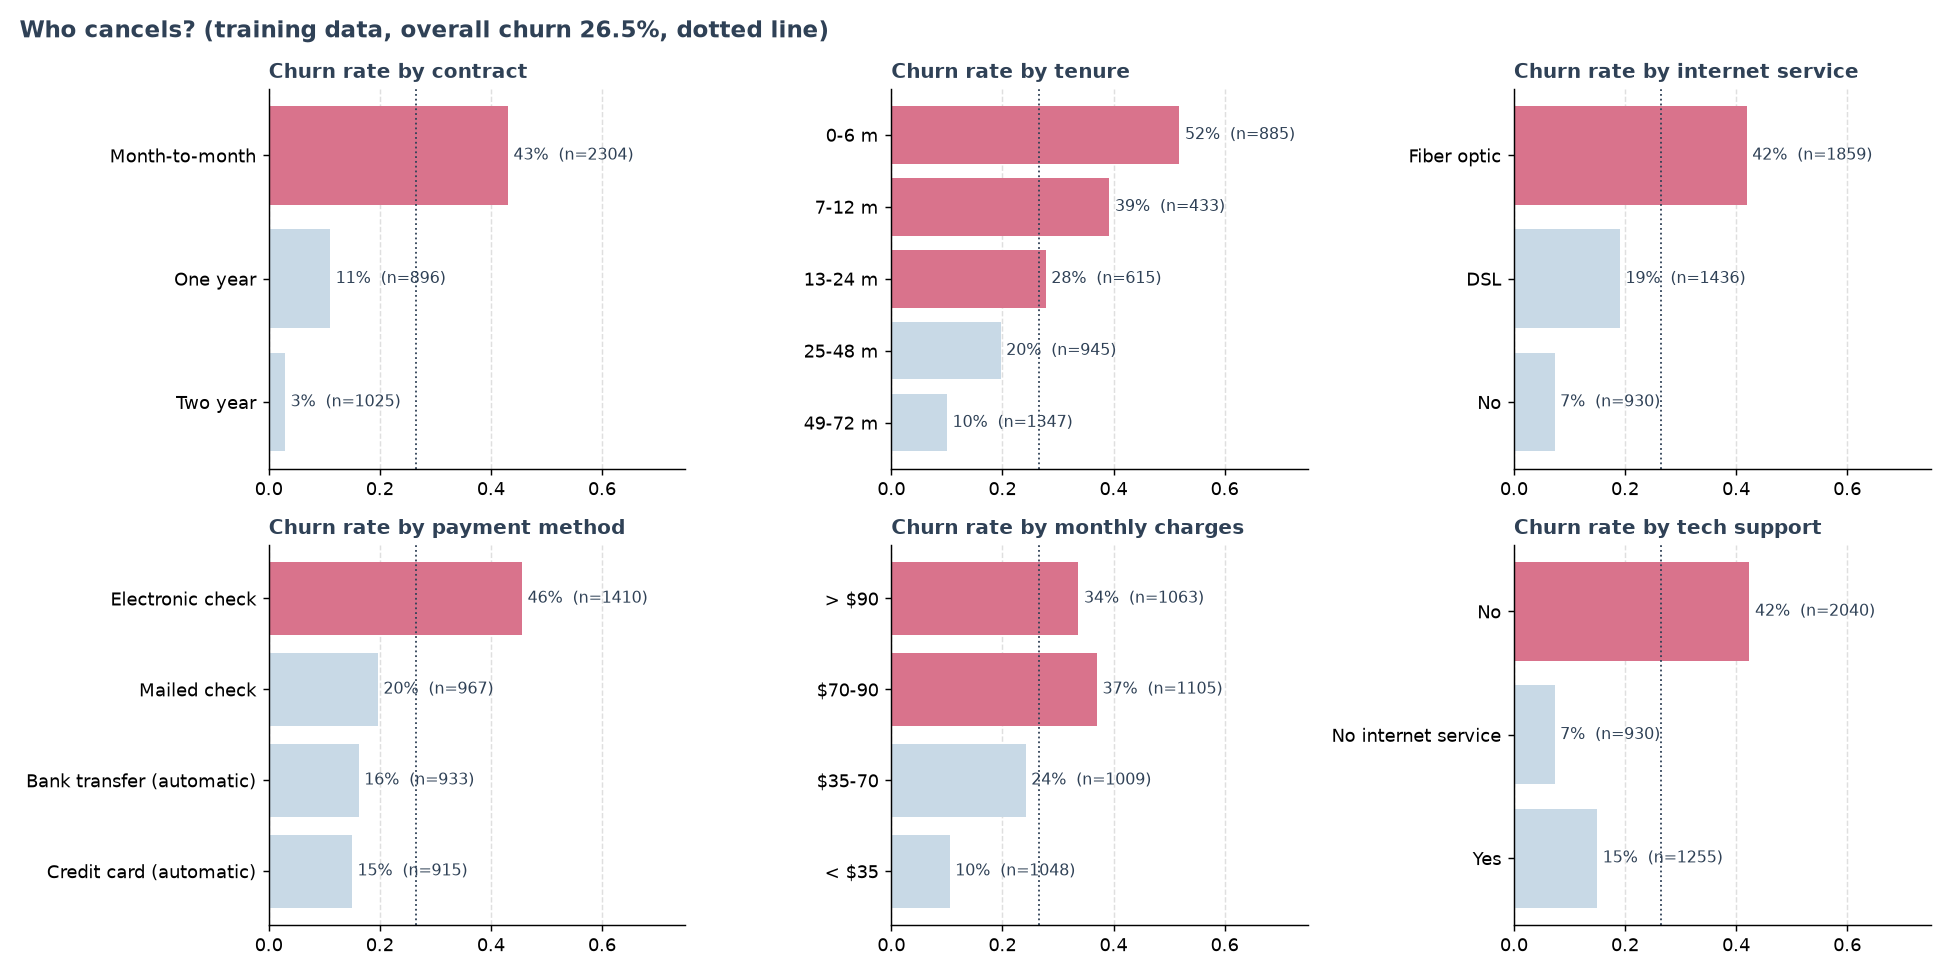

In [4]:
display(Image('../reports/figures/eda_churn_rates.png'))

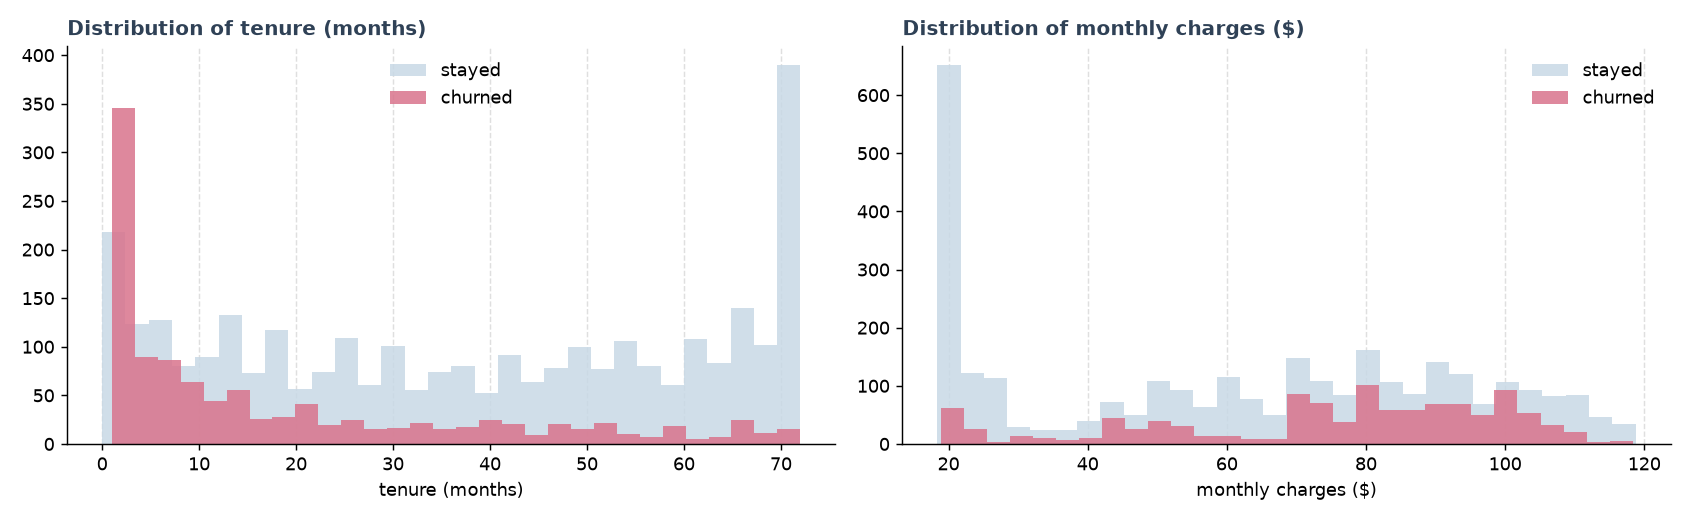

In [5]:
display(Image('../reports/figures/eda_distributions.png'))

**Takeaways:** month-to-month contracts (43%), the first 6 months (52%), fiber optic (42%), electronic check (46%) and no tech support (42%) all churn far above the 26.5% average.

## 3. Baseline vs. improved models, and class imbalance

PR-AUC is the main metric: with 26.5% churn, accuracy rewards doing nothing (73.5% for 'nobody churns').

In [6]:
pd.read_csv('../reports/model_comparison.csv').round(3)

,model,family,imbalance,cv_pr_auc,pr_auc,roc_auc,accuracy,precision@0.5,recall@0.5,f1@0.5
0,Always 'stays',no model,-,NaN,0.265,0.500,0.735,0.000,0.000,0.000
1,Business rule,no model,-,NaN,0.542,0.809,0.659,0.432,0.906,0.585
2,"Logistic regression, raw columns",baseline,none,0.664,0.679,0.860,0.825,0.703,0.594,0.643
3,"Logistic regression, raw columns",baseline,class weights,0.660,0.678,0.860,0.752,0.521,0.824,0.638
4,Logistic regression + engineered features,improved,none,0.674,0.692,0.864,0.818,0.701,0.545,0.614
5,Logistic regression + engineered features,improved,class weights,0.673,0.693,0.863,0.749,0.517,0.824,0.635
6,Logistic regression + engineered features,improved,SMOTE,0.670,0.689,0.860,0.744,0.512,0.816,0.629
7,Logistic regression + engineered features,improved,undersampling,0.669,0.693,0.862,0.746,0.513,0.834,0.635
8,Random forest,improved,class weights,0.663,0.667,0.855,0.784,0.570,0.765,0.653
9,Gradient boosting (tuned),improved,none,0.668,0.684,0.859,0.813,0.696,0.527,0.600


* The engineered features improve the logistic regression; random forest and gradient boosting don't beat it.
* Class weights, SMOTE and undersampling give the same ranking: they only move the scores. So the imbalance is handled with the threshold.

## 4. Threshold from the business case

Contact = $5, offer = 20% off for 3 months, saves 30% of churners, a saved customer = 12 months of revenue. Pick the highest threshold that keeps 98% of the best net value (validation).

In [7]:
pd.read_csv('../reports/threshold_policies_val.csv')[['policy','threshold','contacted','precision','recall','net_value']].round(3)

,policy,threshold,contacted,precision,recall,net_value
0,Contact nobody,1.010,0,0.000,0.000,0.00
1,Contact everyone,0.000,1409,0.265,1.000,35720.81
2,Default threshold 0.5,0.500,291,0.701,0.545,42073.35
3,Best F1,0.350,482,0.589,0.759,53236.22
4,Top 20% riskiest (capacity),0.506,282,0.706,0.532,41077.83
5,Highest net value,0.190,713,0.468,0.893,54455.66
6,"Recommended (98% of best value, fewest contacts)",0.320,521,0.564,0.786,53933.93


In [8]:
s = pd.read_csv('../reports/threshold_sensitivity.csv')
s.pivot_table(index=['save_rate', 'value_months'], columns='discount', values='best_threshold')

discount                 0.1   0.2   0.3
save_rate value_months                  
0.15      6             0.49  0.72  1.01
          12            0.36  0.49  0.49
          24            0.20  0.32  0.38
0.30      6             0.36  0.49  0.49
          12            0.20  0.32  0.38
          24            0.11  0.19  0.22
0.50      6             0.22  0.36  0.42
          12            0.15  0.21  0.23
          24            0.11  0.12  0.16

## 5. Test results (used once)

In [9]:
r = json.load(open('../reports/test_results.json'))
{k: r[k] for k in ['threshold', 'improved', 'baseline', 'pr_auc_diff', 'gains']}

{'threshold': 0.32,
 'improved': {'pr_auc': 0.651410270629382, 'roc_auc': 0.8385362577178435},
 'baseline': {'pr_auc': 0.6204263399323267, 'roc_auc': 0.8328786587098608},
 'pr_auc_diff': {'diff': 0.030983930697055295,
  'ci95': [0.014036751163136876, 0.04752305605172622]},
 'gains': {'top_10%': 0.27540106951871657,
  'top_20%': 0.4893048128342246,
  'top_30%': 0.6470588235294118,
  'top_40%': 0.7780748663101604,
  'top_50%': 0.8743315508021391}}

In [10]:
pd.read_csv('../reports/test_policies.csv')[['policy','threshold','contacted','precision','recall','net_value']].round(3)

,policy,threshold,contacted,precision,recall,net_value
0,Contact nobody,1.010,0,0.000,0.000,0.00
1,Contact everyone,0.000,1409,0.265,1.000,39773.27
2,Default threshold 0.5,0.500,295,0.651,0.513,38970.34
3,Best F1,0.310,528,0.538,0.759,52023.06
4,Top 20% riskiest (capacity),0.516,282,0.652,0.492,37392.87
5,Highest net value,0.180,719,0.460,0.885,55363.85
6,"Recommended (98% of best value, fewest contacts)",0.320,519,0.541,0.751,51785.22


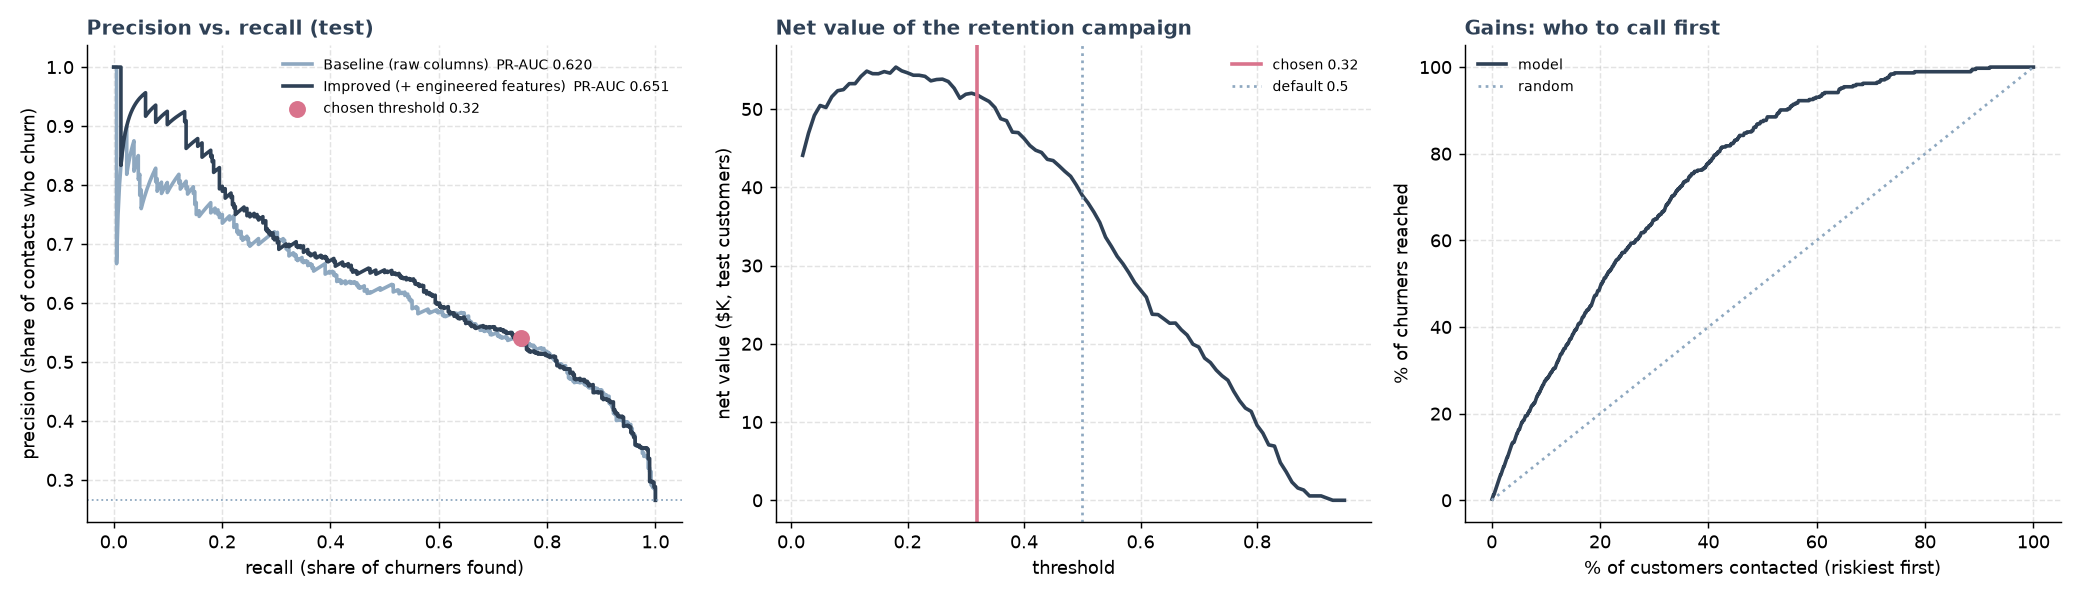

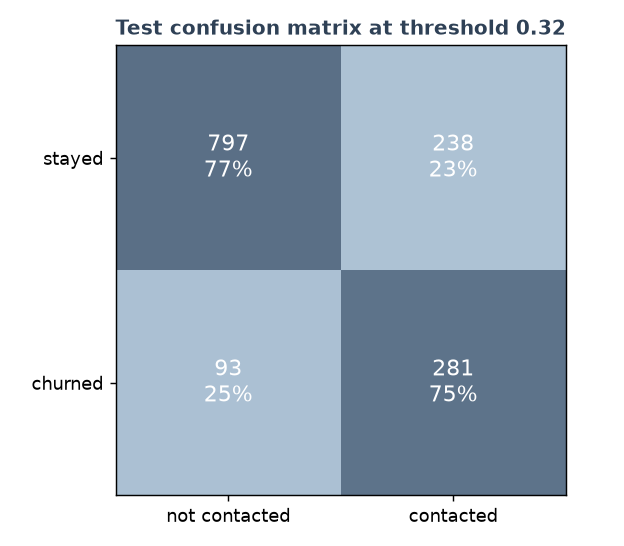

In [11]:
display(Image('../reports/figures/test_evaluation.png'))
display(Image('../reports/figures/confusion_matrix.png'))

## 6. Explainability and fairness

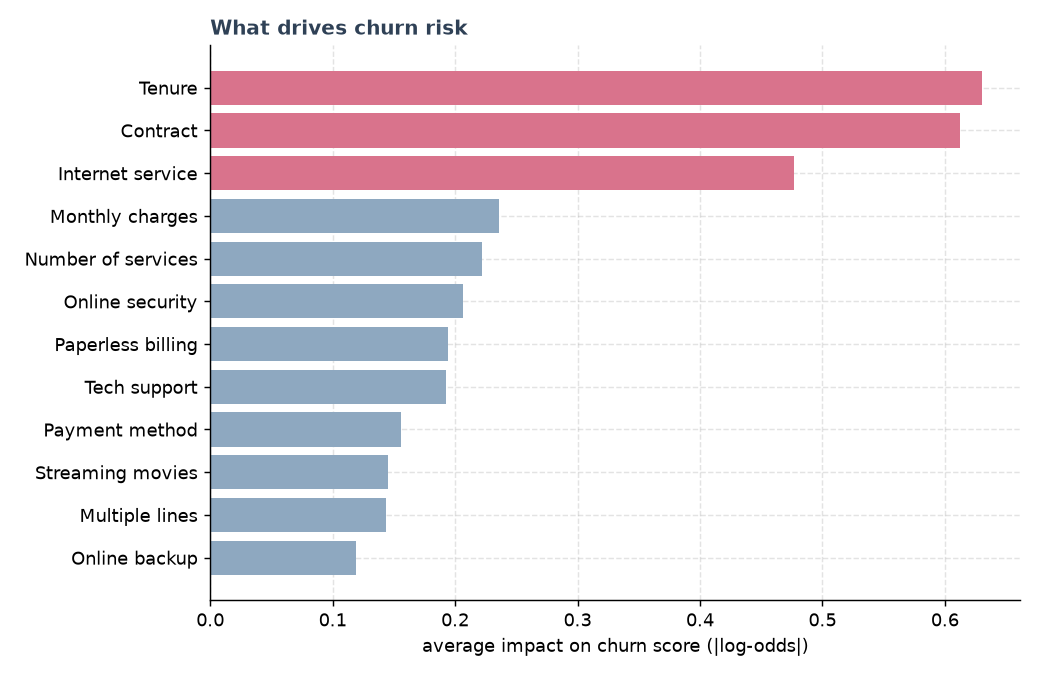

In [12]:
display(Image('../reports/figures/feature_importance.png'))

In [13]:
import joblib
from src.explain import Explainer
from src.data import load
model = joblib.load('../models/churn_model.joblib')
ex = Explainer(model, load('train'))
scores = pd.read_csv('../reports/test_scores.csv').sort_values('score', ascending=False)
test = load('test').set_index('customerID')
for cid in scores.customerID.head(5):
    row = test.loc[cid].copy(); row['customerID'] = cid
    print(cid, f"{scores.set_index('customerID').loc[cid, 'score']:.0%}", ex.reasons(row))

9300-AGZNL 93% ['Customer for 1 month', 'Month-to-month contract', 'Internet: Fiber optic']
0295-PPHDO 92% ['Customer for 1 month', 'Month-to-month contract', 'Internet: Fiber optic']
7851-WZEKY 89% ['Customer for 2 months', 'Month-to-month contract', 'Internet: Fiber optic']
6230-BSUXY 88% ['Customer for 1 month', 'Month-to-month contract', 'Internet: Fiber optic']
9248-OJYKK 88% ['Customer for 1 month', 'Month-to-month contract', 'Internet: Fiber optic']


In [14]:
pd.read_csv('../reports/fairness.csv').round(3)

,attribute,group,customers,churn_rate,flagged_rate,recall,precision
0,gender,Female,714,0.290,0.394,0.754,0.555
1,gender,Male,695,0.240,0.342,0.749,0.525
2,SeniorCitizen,Not senior,1170,0.232,0.310,0.713,0.534
3,SeniorCitizen,Senior,239,0.427,0.653,0.853,0.558
4,Partner,No,720,0.326,0.492,0.821,0.545
5,Partner,Yes,689,0.202,0.239,0.633,0.533
6,Dependents,No,975,0.310,0.456,0.795,0.539
7,Dependents,Yes,434,0.166,0.171,0.569,0.554


## 7. Score a new customer

In [15]:
from src.service import ChurnService
svc = ChurnService()
svc.score_customer({'gender': 'Female', 'SeniorCitizen': 0, 'Partner': 'No', 'Dependents': 'No', 'tenure': 2,
    'PhoneService': 'Yes', 'MultipleLines': 'No', 'InternetService': 'Fiber optic', 'OnlineSecurity': 'No',
    'OnlineBackup': 'No', 'DeviceProtection': 'No', 'TechSupport': 'No', 'StreamingTV': 'Yes',
    'StreamingMovies': 'No', 'Contract': 'Month-to-month', 'PaperlessBilling': 'Yes',
    'PaymentMethod': 'Electronic check', 'MonthlyCharges': 89.5, 'TotalCharges': 179.0})

{'churn_probability': 0.7777,
 'risk_band': 'High',
 'contact': True,
 'threshold': 0.32,
 'reasons': ['Customer for 2 months',
  'Month-to-month contract',
  'Internet: Fiber optic'],
 'protective': ['Pays $90 a month', 'Multiple lines: no'],
 'offer_cost': 58.7,
 'expected_value_if_contacted': 191.88}

See `reports/model_report.md` for the full discussion and limitations.